Pre-COVID (2010–2019): RMSE = 1.1650
COVID Crash (2020): RMSE = 2.0475
Post-COVID (2021–2023): RMSE = 1.1746


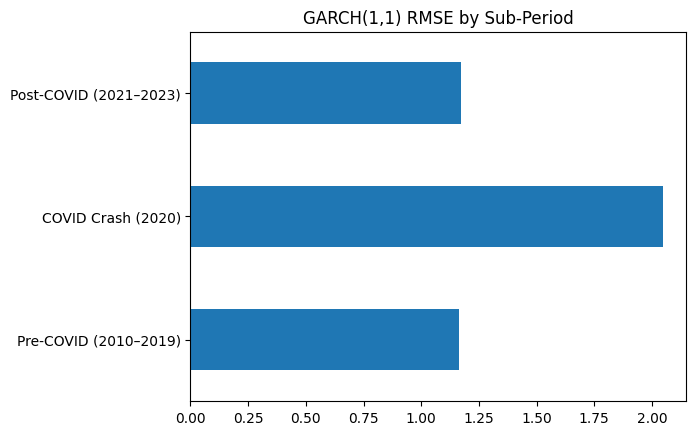

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from arch import arch_model
from sklearn.metrics import mean_squared_error

# Load processed data
df = pd.read_csv("../data/processed/AAPL_processed.csv", parse_dates=["Date"])
df.set_index("Date", inplace=True)
returns = df["log_return"].dropna() * 100
realized = np.sqrt(df["squared_return"].dropna()) * 100

# Function to evaluate GARCH(1,1) on a sub-period
def evaluate_subsample(start, end):
    sub_returns = returns.loc[start:end]
    sub_realized = realized.loc[start:end]
    model = arch_model(sub_returns, vol="Garch", p=1, q=1)
    res = model.fit(disp="off")
    cond_vol = res.conditional_volatility.reindex(sub_realized.index)
    rmse = np.sqrt(mean_squared_error(sub_realized, cond_vol))
    return rmse, res

# Example: pre vs post COVID
periods = {
    "Pre-COVID (2010–2019)": ("2010-01-01", "2019-12-31"),
    "COVID Crash (2020)": ("2020-01-01", "2020-12-31"),
    "Post-COVID (2021–2023)": ("2021-01-01", "2023-12-31")
}

results = {}
for label, (s, e) in periods.items():
    rmse, res = evaluate_subsample(s, e)
    results[label] = rmse
    print(f"{label}: RMSE = {rmse:.4f}")

pd.Series(results).plot(kind="barh", title="GARCH(1,1) RMSE by Sub-Period")
plt.show()
